In [14]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

COLORS = [
    '#013162',  # A/E
    '#2a9d8f',  # VAE 1 SIGMA
    '#ffbf00',  # VAE 3 SIGMA
    '#D602B3',  # DTC ACF
    '#82bf00d4',  # DTC EUC
    '#FF6F00',  # DTC CID
]

plt.rcParams['axes.labelsize'] = 16
plt.rcParams['xtick.labelsize'] = 14   # numbers on the axes (uncomment if needed)
plt.rcParams['ytick.labelsize'] = 14


In [15]:
# ------------------------------
# ------------ DATI ------------
# ------------------------------

MODELS = [
    'A/E',
    'VAE\n$\\pm 1 \\sigma$',
    'VAE\n$\\pm 3 \\sigma$',
    'DTC\nACF',
    'DTC\nEUC',
    'DTC\nCID',
]

# Detector V08682A
y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])

y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

# Detector V08682B
y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])

y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])


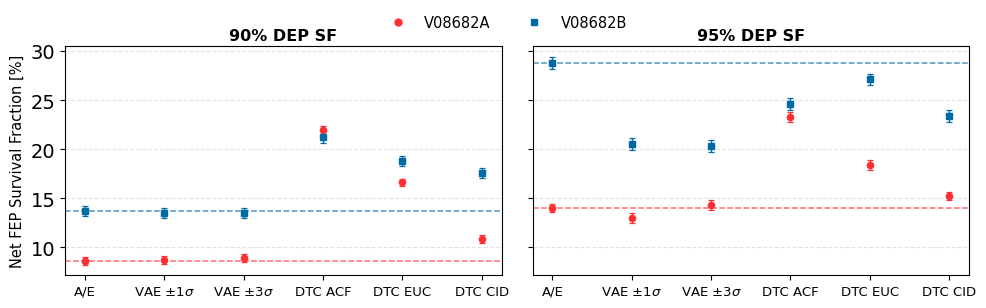

In [16]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# Modelli e valori
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC ACF',
    'DTC EUC',
    'DTC CID',
]

y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Colori per detector
COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.0

# Due subplot affiancati con sharey=True
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3), sharey=True)


def plot_subplot(ax, title_text, y_A, err_A, y_B, err_B, is_left=False):
  # Linee orizzontali tratteggiate di riferimento al valore A/E (indice 0)
  ax.axhline(
      y=y_A[0],
      color=COLOR_A,
      linestyle='--',
      linewidth=1.1,
      alpha=0.7,
      zorder=1,
  )
  ax.axhline(
      y=y_B[0],
      color=COLOR_B,
      linestyle='--',
      linewidth=1.1,
      alpha=0.7,
      zorder=1,
  )

  # Detector V08682A: Cerchio pieno
  ax.errorbar(
      x - dx_det,
      y_A,
      yerr=err_A,
      fmt='o',
      color=COLOR_A,
      markerfacecolor=COLOR_A,
      markeredgecolor=COLOR_A,
      ecolor=COLOR_A,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Detector V08682B: Quadrato pieno
  ax.errorbar(
      x + dx_det,
      y_B,
      yerr=err_B,
      fmt='s',
      color=COLOR_B,
      markerfacecolor=COLOR_B,
      markeredgecolor=COLOR_B,
      ecolor=COLOR_B,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Titolo
  ax.text(
      0.5,
      1.08,
      title_text,
      transform=ax.transAxes,
      ha='center',
      va='top',
      fontsize=11.5,
      fontweight='bold',
  )

  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=9.5)
  if is_left:
    ax.set_ylabel('Net FEP Survival Fraction [%]', fontsize=10.5)
  ax.grid(True, linestyle='--', alpha=0.35, axis='y')


# Disegna i due tagli
plot_subplot(
    ax1, '90% DEP SF', y_A_90, err_A_90, y_B_90, err_B_90, is_left=True
)
plot_subplot(
    ax2, '95% DEP SF', y_A_95, err_A_95, y_B_95, err_B_95, is_left=False
)

# Legenda unica esterna
legend_handles = [
    mlines.Line2D(
        [],
        [],
        marker='o',
        markerfacecolor=COLOR_A,
        markeredgecolor=COLOR_A,
        linestyle='None',
        markersize=5,
        label='V08682A',
    ),
    mlines.Line2D(
        [],
        [],
        marker='s',
        markerfacecolor=COLOR_B,
        markeredgecolor=COLOR_B,
        linestyle='None',
        markersize=5,
        label='V08682B',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.51, 0.90),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout()
plt.savefig('plot_finale.pdf')
plt.show()

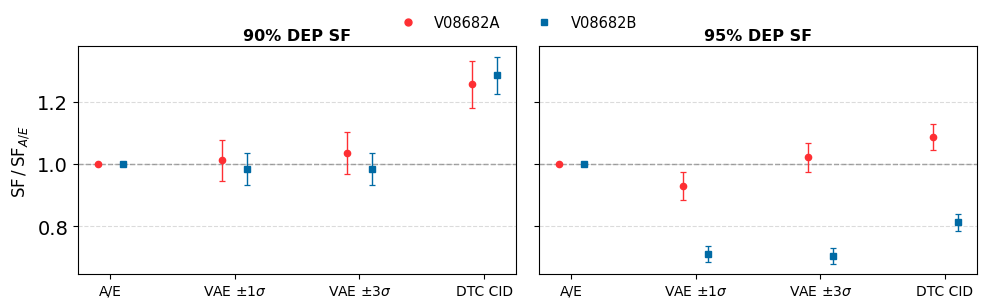

In [17]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# Modelli selezionati (esclusi ACF ed EUC)
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC CID',
]

# Indici corrispondenti ai modelli selezionati:
# 0: A/E, 1: VAE ±1σ, 2: VAE ±3σ, 5: DTC CID
idx_keep = [0, 1, 2, 5]

# Dati originali
y_A_90_full = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90_full = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95_full = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95_full = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90_full = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90_full = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95_full = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95_full = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Selezione modelli
y_A_90 = y_A_90_full[idx_keep]
err_A_90 = err_A_90_full[idx_keep]
y_A_95 = y_A_95_full[idx_keep]
err_A_95 = err_A_95_full[idx_keep]

y_B_90 = y_B_90_full[idx_keep]
err_B_90 = err_B_90_full[idx_keep]
y_B_95 = y_B_95_full[idx_keep]
err_B_95 = err_B_95_full[idx_keep]

# Colori per detector
COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.1


# -------------------------------------------------------------------------
# Calcolo rapporto R = SF_algoritmo / SF_AE e propagazione incertezze
# -------------------------------------------------------------------------
def compute_ratio(y, err):
  y_ae = y[0]
  err_ae = err[0]

  # Rapporto
  ratio = y / y_ae

  # Propagazione errore sul rapporto
  rel_err_sq = (err / y) ** 2 + (err_ae / y_ae) ** 2
  ratio_err = ratio * np.sqrt(rel_err_sq)
  ratio_err[0] = 0.0  # Per A/E il rapporto con se stesso è identicamente 1

  return ratio, ratio_err


ratio_A_90, err_ratio_A_90 = compute_ratio(y_A_90, err_A_90)
ratio_A_95, err_ratio_A_95 = compute_ratio(y_A_95, err_A_95)

ratio_B_90, err_ratio_B_90 = compute_ratio(y_B_90, err_B_90)
ratio_B_95, err_ratio_B_95 = compute_ratio(y_B_95, err_B_95)

# -------------------------------------------------------------------------
# Plotting
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3), sharey=True)


def plot_subplot(
    ax, title_text, ratio_A, err_A, ratio_B, err_B, is_left=False
):
  # Linea di riferimento a 1.0 (valore di A/E)
  ax.axhline(
      y=1.0, color='gray', linestyle='--', linewidth=1.0, alpha=0.8, zorder=1
  )

  # Detector V08682A: Cerchio pieno
  ax.errorbar(
      x - dx_det,
      ratio_A,
      yerr=err_A,
      fmt='o',
      color=COLOR_A,
      markerfacecolor=COLOR_A,
      markeredgecolor=COLOR_A,
      ecolor=COLOR_A,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Detector V08682B: Quadrato pieno
  ax.errorbar(
      x + dx_det,
      ratio_B,
      yerr=err_B,
      fmt='s',
      color=COLOR_B,
      markerfacecolor=COLOR_B,
      markeredgecolor=COLOR_B,
      ecolor=COLOR_B,
      elinewidth=1.0,
      capsize=2.5,
      capthick=0.9,
      markersize=4.5,
      zorder=3,
  )

  # Titolo interno al plot
  ax.text(
      0.5,
      1.08,
      title_text,
      transform=ax.transAxes,
      ha='center',
      va='top',
      fontsize=11.5,
      fontweight='bold',
  )

  ax.set_xticks(x)
  ax.set_xticklabels(MODELS, fontsize=10)
  if is_left:
    ax.set_ylabel(r'$\mathrm{SF} \,/\, \mathrm{SF}_{A/E}$', fontsize=12)
  ax.grid(True, linestyle='--', alpha=0.45, axis='y')


# Disegna i due subplot
plot_subplot(
    ax1,
    '90% DEP SF',
    ratio_A_90,
    err_ratio_A_90,
    ratio_B_90,
    err_ratio_B_90,
    is_left=True,
)
plot_subplot(
    ax2,
    '95% DEP SF',
    ratio_A_95,
    err_ratio_A_95,
    ratio_B_95,
    err_ratio_B_95,
    is_left=False,
)

# Legenda esterna superiore
legend_handles = [
    mlines.Line2D(
        [],
        [],
        marker='o',
        markerfacecolor=COLOR_A,
        markeredgecolor=COLOR_A,
        linestyle='None',
        markersize=5,
        label='V08682A',
    ),
    mlines.Line2D(
        [],
        [],
        marker='s',
        markerfacecolor=COLOR_B,
        markeredgecolor=COLOR_B,
        linestyle='None',
        markersize=5,
        label='V08682B',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.52, 0.90),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout()
plt.savefig('plot_finale_rapporto.pdf', dpi=300)
plt.show()

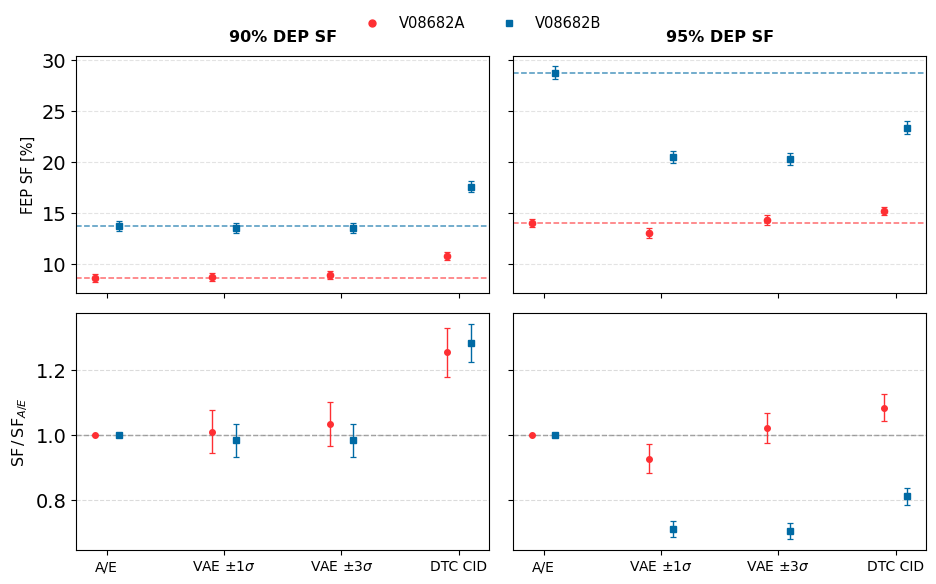

In [18]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------------------------------
# Dati e configurazione modelli
# -------------------------------------------------------------------------
MODELS = [
    'A/E',
    r'VAE $\pm 1\sigma$',
    r'VAE $\pm 3\sigma$',
    'DTC CID',
]
idx_keep = [0, 1, 2, 5]

# Dati originali
y_A_90_full = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90_full = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])
y_A_95_full = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95_full = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

y_B_90_full = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90_full = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])
y_B_95_full = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95_full = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

# Selezione modelli
y_A_90 = y_A_90_full[idx_keep]
err_A_90 = err_A_90_full[idx_keep]
y_A_95 = y_A_95_full[idx_keep]
err_A_95 = err_A_95_full[idx_keep]

y_B_90 = y_B_90_full[idx_keep]
err_B_90 = err_B_90_full[idx_keep]
y_B_95 = y_B_95_full[idx_keep]
err_B_95 = err_B_95_full[idx_keep]

COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.10


# -------------------------------------------------------------------------
# Calcolo rapporto R = SF_algoritmo / SF_AE e propagazione incertezze
# -------------------------------------------------------------------------
def compute_ratio(y, err):
  y_ae = y[0]
  err_ae = err[0]
  ratio = y / y_ae
  rel_err_sq = (err / y) ** 2 + (err_ae / y_ae) ** 2
  ratio_err = ratio * np.sqrt(rel_err_sq)
  ratio_err[0] = 0.0
  return ratio, ratio_err


ratio_A_90, err_ratio_A_90 = compute_ratio(y_A_90, err_A_90)
ratio_A_95, err_ratio_A_95 = compute_ratio(y_A_95, err_A_95)
ratio_B_90, err_ratio_B_90 = compute_ratio(y_B_90, err_B_90)
ratio_B_95, err_ratio_B_95 = compute_ratio(y_B_95, err_B_95)

# -------------------------------------------------------------------------
# Plot 2x2
# -------------------------------------------------------------------------
fig, axes = plt.subplots(
    2, 2, figsize=(9.5, 5.8), sharex=True, sharey='row'
)

# --- RIGA 1: Valori assoluti SF [%] ---
# Colonna 1: 90% DEP SF
axes[0, 0].axhline(
    y=y_A_90[0],
    color=COLOR_A,
    linestyle='--',
    linewidth=1.1,
    alpha=0.7,
    zorder=1,
)
axes[0, 0].axhline(
    y=y_B_90[0],
    color=COLOR_B,
    linestyle='--',
    linewidth=1.1,
    alpha=0.7,
    zorder=1,
)
axes[0, 0].errorbar(
    x - dx_det,
    y_A_90,
    yerr=err_A_90,
    fmt='o',
    color=COLOR_A,
    markerfacecolor=COLOR_A,
    markeredgecolor=COLOR_A,
    ecolor=COLOR_A,
    elinewidth=1.0,
    capsize=2.5,
    capthick=0.9,
    markersize=4.5,
    zorder=3,
)
axes[0, 0].errorbar(
    x + dx_det,
    y_B_90,
    yerr=err_B_90,
    fmt='s',
    color=COLOR_B,
    markerfacecolor=COLOR_B,
    markeredgecolor=COLOR_B,
    ecolor=COLOR_B,
    elinewidth=1.0,
    capsize=2.5,
    capthick=0.9,
    markersize=4.5,
    zorder=3,
)
axes[0, 0].set_ylabel('FEP SF [%]', fontsize=10.5)
axes[0, 0].set_title('90% DEP SF', fontsize=11.5, fontweight='bold', pad=10)
axes[0, 0].grid(True, linestyle='--', alpha=0.35, axis='y')

# Colonna 2: 95% DEP SF
axes[0, 1].axhline(
    y=y_A_95[0],
    color=COLOR_A,
    linestyle='--',
    linewidth=1.1,
    alpha=0.7,
    zorder=1,
)
axes[0, 1].axhline(
    y=y_B_95[0],
    color=COLOR_B,
    linestyle='--',
    linewidth=1.1,
    alpha=0.7,
    zorder=1,
)
axes[0, 1].errorbar(
    x - dx_det,
    y_A_95,
    yerr=err_A_95,
    fmt='o',
    color=COLOR_A,
    markerfacecolor=COLOR_A,
    markeredgecolor=COLOR_A,
    ecolor=COLOR_A,
    elinewidth=1.0,
    capsize=2.5,
    capthick=0.9,
    markersize=4.5,
    zorder=3,
)
axes[0, 1].errorbar(
    x + dx_det,
    y_B_95,
    yerr=err_B_95,
    fmt='s',
    color=COLOR_B,
    markerfacecolor=COLOR_B,
    markeredgecolor=COLOR_B,
    ecolor=COLOR_B,
    elinewidth=1.0,
    capsize=2.5,
    capthick=0.9,
    markersize=4.5,
    zorder=3,
)
axes[0, 1].set_title('95% DEP SF', fontsize=11.5, fontweight='bold', pad=10)
axes[0, 1].grid(True, linestyle='--', alpha=0.35, axis='y')

# --- RIGA 2: Rapporto SF / SF_AE ---
# Colonna 1: 90% DEP SF
axes[1, 0].axhline(
    y=1.0, color='gray', linestyle='--', linewidth=1.0, alpha=0.8, zorder=1
)
axes[1, 0].errorbar(
    x - dx_det,
    ratio_A_90,
    yerr=err_ratio_A_90,
    fmt='o',
    color=COLOR_A,
    markerfacecolor=COLOR_A,
    markeredgecolor=COLOR_A,
    ecolor=COLOR_A,
    elinewidth=1.0,
    capsize=2.5,
    capthick=0.9,
    markersize=4,
    zorder=3,
)
axes[1, 0].errorbar(
    x + dx_det,
    ratio_B_90,
    yerr=err_ratio_B_90,
    fmt='s',
    color=COLOR_B,
    markerfacecolor=COLOR_B,
    markeredgecolor=COLOR_B,
    ecolor=COLOR_B,
    elinewidth=1.0,
    capsize=2.5,
    capthick=0.9,
    markersize=4,
    zorder=3,
)
axes[1, 0].set_ylabel(r'$\mathrm{SF} \,/\, \mathrm{SF}_{A/E}$', fontsize=11.5)
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(MODELS, fontsize=10)
axes[1, 0].grid(True, linestyle='--', alpha=0.45, axis='y')

# Colonna 2: 95% DEP SF
axes[1, 1].axhline(
    y=1.0, color='gray', linestyle='--', linewidth=1.0, alpha=0.8, zorder=1
)
axes[1, 1].errorbar(
    x - dx_det,
    ratio_A_95,
    yerr=err_ratio_A_95,
    fmt='o',
    color=COLOR_A,
    markerfacecolor=COLOR_A,
    markeredgecolor=COLOR_A,
    ecolor=COLOR_A,
    elinewidth=1.0,
    capsize=2.5,
    capthick=0.9,
    markersize=4,
    zorder=3,
)
axes[1, 1].errorbar(
    x + dx_det,
    ratio_B_95,
    yerr=err_ratio_B_95,
    fmt='s',
    color=COLOR_B,
    markerfacecolor=COLOR_B,
    markeredgecolor=COLOR_B,
    ecolor=COLOR_B,
    elinewidth=1.0,
    capsize=2.5,
    capthick=0.9,
    markersize=4,
    zorder=3,
)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(MODELS, fontsize=10)
axes[1, 1].grid(True, linestyle='--', alpha=0.45, axis='y')

# --- Legenda unica esterna in alto ---
legend_handles = [
    mlines.Line2D(
        [],
        [],
        marker='o',
        markerfacecolor=COLOR_A,
        markeredgecolor=COLOR_A,
        linestyle='None',
        markersize=5,
        label='V08682A',
    ),
    mlines.Line2D(
        [],
        [],
        marker='s',
        markerfacecolor=COLOR_B,
        markeredgecolor=COLOR_B,
        linestyle='None',
        markersize=5,
        label='V08682B',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.51, 0.94),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig('plot_finale_2x2.pdf', dpi=300)
plt.show()

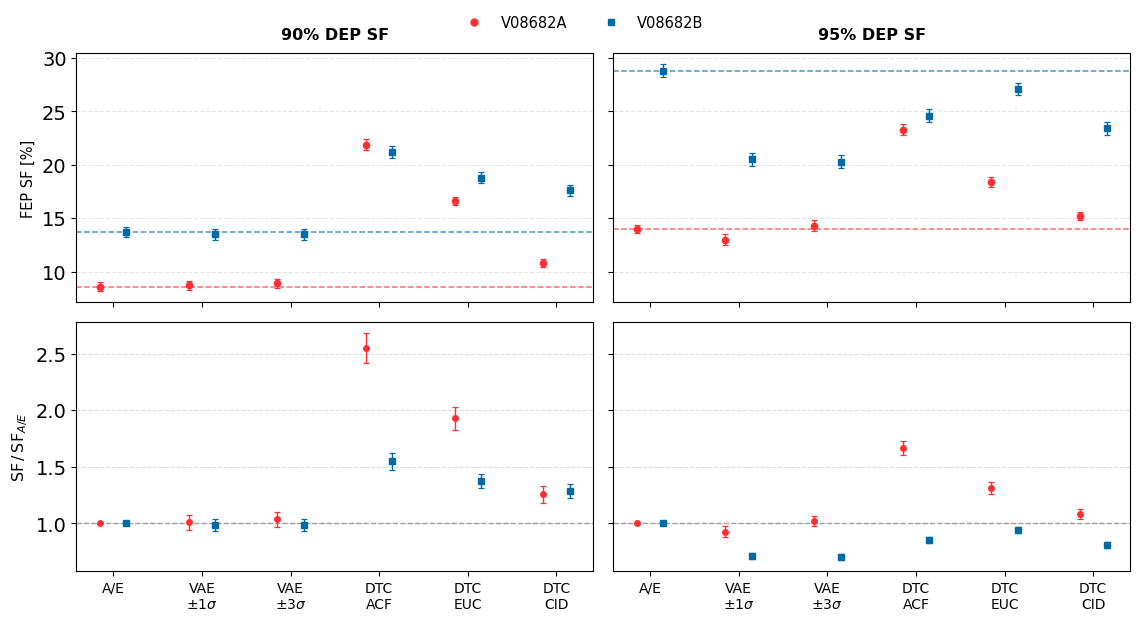

In [20]:
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np

# -------------------------------------------------------------------------
# Dati e configurazione modelli (TUTTE le metriche)
# -------------------------------------------------------------------------
MODELS = [
    'A/E',
    'VAE\n$\\pm 1 \\sigma$',
    'VAE\n$\\pm 3 \\sigma$',
    'DTC\nACF',
    'DTC\nEUC',
    'DTC\nCID',
]

# Detector V08682A
y_A_90 = np.array([8.6, 8.7, 8.9, 21.9, 16.6, 10.8])
err_A_90 = np.array([0.4, 0.4, 0.4, 0.5, 0.4, 0.4])

y_A_95 = np.array([14.0, 13.0, 14.3, 23.3, 18.4, 15.2])
err_A_95 = np.array([0.4, 0.5, 0.5, 0.5, 0.5, 0.4])

# Detector V08682B
y_B_90 = np.array([13.7, 13.5, 13.5, 21.2, 18.8, 17.6])
err_B_90 = np.array([0.5, 0.5, 0.5, 0.6, 0.5, 0.5])

y_B_95 = np.array([28.8, 20.5, 20.3, 24.6, 27.1, 23.4])
err_B_95 = np.array([0.6, 0.6, 0.6, 0.6, 0.6, 0.6])

COLOR_A = '#fe2f33'
COLOR_B = '#006aa4'

x = np.arange(len(MODELS))
dx_det = 0.15 # Leggermente aumentato per separare meglio i punti dato che ci sono più etichette

# -------------------------------------------------------------------------
# Calcolo rapporto R = SF_algoritmo / SF_AE e propagazione incertezze
# -------------------------------------------------------------------------
def compute_ratio(y, err):
    y_ae = y[0]
    err_ae = err[0]
    ratio = y / y_ae
    rel_err_sq = (err / y) ** 2 + (err_ae / y_ae) ** 2
    ratio_err = ratio * np.sqrt(rel_err_sq)
    ratio_err[0] = 0.0
    return ratio, ratio_err

ratio_A_90, err_ratio_A_90 = compute_ratio(y_A_90, err_A_90)
ratio_A_95, err_ratio_A_95 = compute_ratio(y_A_95, err_A_95)
ratio_B_90, err_ratio_B_90 = compute_ratio(y_B_90, err_B_90)
ratio_B_95, err_ratio_B_95 = compute_ratio(y_B_95, err_B_95)

# -------------------------------------------------------------------------
# Plot 2x2
# -------------------------------------------------------------------------
# Aumentato il figsize per far respirare le 6 etichette sull'asse x
fig, axes = plt.subplots(
    2, 2, figsize=(11.5, 6.2), sharex=True, sharey='row'
)

# --- RIGA 1: Valori assoluti SF [%] ---
# Colonna 1: 90% DEP SF
axes[0, 0].axhline(
    y=y_A_90[0], color=COLOR_A, linestyle='--', linewidth=1.1, alpha=0.7, zorder=1,
)
axes[0, 0].axhline(
    y=y_B_90[0], color=COLOR_B, linestyle='--', linewidth=1.1, alpha=0.7, zorder=1,
)
axes[0, 0].errorbar(
    x - dx_det, y_A_90, yerr=err_A_90, fmt='o', color=COLOR_A,
    markerfacecolor=COLOR_A, markeredgecolor=COLOR_A, ecolor=COLOR_A,
    elinewidth=1.0, capsize=2.5, capthick=0.9, markersize=4.5, zorder=3,
)
axes[0, 0].errorbar(
    x + dx_det, y_B_90, yerr=err_B_90, fmt='s', color=COLOR_B,
    markerfacecolor=COLOR_B, markeredgecolor=COLOR_B, ecolor=COLOR_B,
    elinewidth=1.0, capsize=2.5, capthick=0.9, markersize=4.5, zorder=3,
)
axes[0, 0].set_ylabel('FEP SF [%]', fontsize=10.5)
axes[0, 0].set_title('90% DEP SF', fontsize=11.5, fontweight='bold', pad=10)
axes[0, 0].grid(True, linestyle='--', alpha=0.35, axis='y')

# Colonna 2: 95% DEP SF
axes[0, 1].axhline(
    y=y_A_95[0], color=COLOR_A, linestyle='--', linewidth=1.1, alpha=0.7, zorder=1,
)
axes[0, 1].axhline(
    y=y_B_95[0], color=COLOR_B, linestyle='--', linewidth=1.1, alpha=0.7, zorder=1,
)
axes[0, 1].errorbar(
    x - dx_det, y_A_95, yerr=err_A_95, fmt='o', color=COLOR_A,
    markerfacecolor=COLOR_A, markeredgecolor=COLOR_A, ecolor=COLOR_A,
    elinewidth=1.0, capsize=2.5, capthick=0.9, markersize=4.5, zorder=3,
)
axes[0, 1].errorbar(
    x + dx_det, y_B_95, yerr=err_B_95, fmt='s', color=COLOR_B,
    markerfacecolor=COLOR_B, markeredgecolor=COLOR_B, ecolor=COLOR_B,
    elinewidth=1.0, capsize=2.5, capthick=0.9, markersize=4.5, zorder=3,
)
axes[0, 1].set_title('95% DEP SF', fontsize=11.5, fontweight='bold', pad=10)
axes[0, 1].grid(True, linestyle='--', alpha=0.35, axis='y')

# --- RIGA 2: Rapporto SF / SF_AE ---
# Colonna 1: 90% DEP SF
axes[1, 0].axhline(y=1.0, color='gray', linestyle='--', linewidth=1.0, alpha=0.8, zorder=1)
axes[1, 0].errorbar(
    x - dx_det, ratio_A_90, yerr=err_ratio_A_90, fmt='o', color=COLOR_A,
    markerfacecolor=COLOR_A, markeredgecolor=COLOR_A, ecolor=COLOR_A,
    elinewidth=1.0, capsize=2.5, capthick=0.9, markersize=4, zorder=3,
)
axes[1, 0].errorbar(
    x + dx_det, ratio_B_90, yerr=err_ratio_B_90, fmt='s', color=COLOR_B,
    markerfacecolor=COLOR_B, markeredgecolor=COLOR_B, ecolor=COLOR_B,
    elinewidth=1.0, capsize=2.5, capthick=0.9, markersize=4, zorder=3,
)
axes[1, 0].set_ylabel(r'$\mathrm{SF} \,/\, \mathrm{SF}_{A/E}$', fontsize=11.5)
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(MODELS, fontsize=10)
axes[1, 0].grid(True, linestyle='--', alpha=0.45, axis='y')

# Colonna 2: 95% DEP SF
axes[1, 1].axhline(y=1.0, color='gray', linestyle='--', linewidth=1.0, alpha=0.8, zorder=1)
axes[1, 1].errorbar(
    x - dx_det, ratio_A_95, yerr=err_ratio_A_95, fmt='o', color=COLOR_A,
    markerfacecolor=COLOR_A, markeredgecolor=COLOR_A, ecolor=COLOR_A,
    elinewidth=1.0, capsize=2.5, capthick=0.9, markersize=4, zorder=3,
)
axes[1, 1].errorbar(
    x + dx_det, ratio_B_95, yerr=err_ratio_B_95, fmt='s', color=COLOR_B,
    markerfacecolor=COLOR_B, markeredgecolor=COLOR_B, ecolor=COLOR_B,
    elinewidth=1.0, capsize=2.5, capthick=0.9, markersize=4, zorder=3,
)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(MODELS, fontsize=10)
axes[1, 1].grid(True, linestyle='--', alpha=0.45, axis='y')

# --- Legenda unica esterna in alto ---
legend_handles = [
    mlines.Line2D(
        [], [], marker='o', markerfacecolor=COLOR_A, markeredgecolor=COLOR_A,
        linestyle='None', markersize=5, label='V08682A',
    ),
    mlines.Line2D(
        [], [], marker='s', markerfacecolor=COLOR_B, markeredgecolor=COLOR_B,
        linestyle='None', markersize=5, label='V08682B',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.51, 0.94),
    ncol=2,
    frameon=False,
    fontsize=10.5,
)

plt.tight_layout(rect=[0, 0, 1, 0.99]) # Aggiornato il rect per non sovrapporre il plot alla legenda
plt.savefig('plot_finale_2x2_tutti.pdf', dpi=300)
plt.show()